In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import pandas as pd 
import statistics 
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
df=pd.read_csv("Housing.csv")
df.head()
print("is the df is null or not :",df.isnull().sum().sum())
print(df["price"].describe())

q3,q1=np.percentile(df['price'],[75,25])
iqr=q3-q1
df_cleanned=df[
	(df['price'] >=q1-(1.5*iqr)) &
	(df['price'] <= q3+(1.5*iqr))
]

q3_a,q1_a=np.percentile(df['area'],[75,25])
iqr=q3-q1
df_cleanned=df[
	(df['area'] >=q1-(1.5*iqr)) &
	(df['area'] <= q3+(1.5*iwr))
]

print("rows before iqr",len(df))

X=df.drop("price",axis=1)
Y=df["price"]


#the data is converted into dumies
X=pd.get_dummies(X,drop_first=True)
X=X.astype(int)


print(X)

xtrain,xtest,ytrain,ytest=train_test_split(X,Y,test_size=0.2,random_state=42)

std=StandardScaler()
xtrainscaler=std.fit_transform(xtrain)
xtestscaler=std.transform(xtest)

model=LinearRegression()
model.fit(xtrainscaler,ytrain)
ypred=model.predict(xtestscaler)
df

r2=r2_score(ytest,ypred)
print(r2)
#mse
mse=mean_squared_error(ytest,ypred)
print(f":{mse:,.2f}")
#mae 
mae=mean_absolute_error(ytest,ypred)
print(f"Mean_Absolute_Error:{mae:,.2f}")

is the df is null or not : 0
count    5.450000e+02
mean     4.766729e+06
std      1.870440e+06
min      1.750000e+06
25%      3.430000e+06
50%      4.340000e+06
75%      5.740000e+06
max      1.330000e+07
Name: price, dtype: float64
rows before iqr 545
     area  bedrooms  bathrooms  stories  parking  mainroad_yes  guestroom_yes  \
0    7420         4          2        3        2             1              0   
1    8960         4          4        4        3             1              0   
2    9960         3          2        2        2             1              0   
3    7500         4          2        2        3             1              0   
4    7420         4          1        2        2             1              1   
..    ...       ...        ...      ...      ...           ...            ...   
540  3000         2          1        1        2             1              0   
541  2400         3          1        1        0             0              0   
542  3620         

Text(0.5, 1.0, 'Actual VS Predicted price')

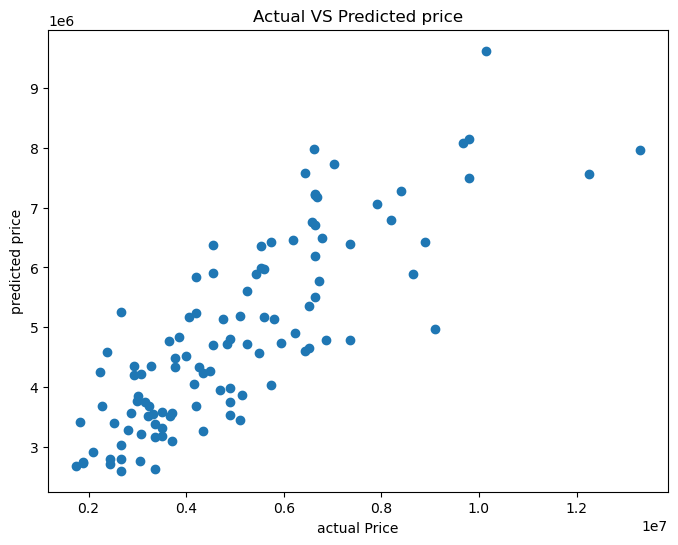

In [5]:

plt.figure(figsize=(8,6))
plt.scatter(ytest,ypred)
plt.xlabel("actual Price")
plt.ylabel("predicted price")
plt.title("Actual VS Predicted price")



In [6]:
df1=df[['price','bedrooms','stories','bathrooms']]
print(df1.min())
print(df1.max())
std=np.std(df1['price'])
print(std)
statistics.stdev(df1['price'])

price        1750000
bedrooms           1
stories            1
bathrooms          1
dtype: int64
price        13300000
bedrooms            6
stories             4
bathrooms           4
dtype: int64
1868722.8281312098


1870439.6156573922